# StreamLoop — Ajuste del Modelo de Cancelación de Clientes (Churn)

## Contexto de Negocio
En StreamLoop, la retención de clientes es crítica. La empresa enfrenta el reto de identificar proactivamente a los usuarios con alto riesgo de cancelar su suscripción.
Desde la perspectiva de negocio, existe una asimetría de costos fundamental:
- **No detectar una cancelación (Falso Negativo)**: Implica la pérdida definitiva del cliente, su valor de vida (LTV) y los ingresos recurrentes asociados.
- **Ofrecer retención a un cliente que no iba a cancelar (Falso Positivo)**: Implica el costo marginal de una campaña, descuento o beneficio de retención, pero el cliente se mantiene en la plataforma.

Por lo tanto, la prioridad del modelo es **maximizar el Recall de la clase positiva (Churn = 1)**, minimizando los Falsos Negativos sin degradar excesivamente la precisión global.

---
## Flujo de Trabajo
1. **Auditoría y Preparación de Datos**: Limpieza determinista y partición estratificada única 80/20.
2. **Línea Base y Primera Evaluación de Test**: Pipeline reproducible con `RandomForestClassifier` por defecto.
3. **Exploración con `RandomizedSearchCV`**: Búsqueda amplia de hiperparámetros en el conjunto de entrenamiento mediante 5-Fold Stratified CV.
4. **Refinamiento con `GridSearchCV`**: Búsqueda focalizada alrededor de las regiones más prometedoras de la búsqueda aleatoria.
5. **Selección del Modelo y Segunda (Última) Evaluación de Test**: Comparación rigurosa de ganancias y contrapartidas frente a la línea base.


In [1]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    recall_score, precision_score, f1_score, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

# Configuración visual
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11
sns.set_theme(style="whitegrid")
print("Librerías importadas correctamente.")


Librerías importadas correctamente.


## 1. Carga, Auditoría y Preparación de Datos

Cargamos el dataset oficial de Telco Customer Churn desde el repositorio fuente o la copia local si ya existe. Realizamos una inspección estricta de:
- Dimensiones y tipos de datos.
- Identificadores únicos (`customerID`) y verificación de duplicados.
- Tratamiento de `TotalCharges`: conversión de espacios en blanco a valores numéricos nulos.
- Codificación binaria de `Churn` (`Yes=1`, `No=0`).
- Conservación de categorías con semántica de negocio como `"No internet service"`.


In [2]:
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
DATA_PATH = os.path.join("..", "data", "Telco-Customer-Churn.csv")

if not os.path.exists(DATA_PATH):
    # Intentar ruta relativa a la raiz del proyecto
    DATA_PATH = os.path.join("data", "Telco-Customer-Churn.csv")
    if not os.path.exists(DATA_PATH):
        os.makedirs(os.path.dirname(DATA_PATH), exist_ok=True)
        print("Descargando dataset...")
        urllib.request.urlretrieve(DATA_URL, DATA_PATH)

df = pd.read_csv(DATA_PATH)
print(f"Dimensiones iniciales: {df.shape}")
print(f"Filas duplicadas completas: {df.duplicated().sum()}")
print(f"IDs de cliente unicos: {df['customerID'].nunique()} de {len(df)}")

# Auditoria de valores en TotalCharges
espacios_total_charges = (df['TotalCharges'].astype(str).str.strip() == '').sum()
print(f"Registros con espacios en blanco en TotalCharges: {espacios_total_charges}")

# Conversion determinista a numerico
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(' ', np.nan), errors='coerce')
print(f"Valores nulos en TotalCharges tras conversion: {df['TotalCharges'].isnull().sum()}")

# Codificacion de variable objetivo Churn (Yes=1, No=0)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
dist_churn = df['Churn'].value_counts()
dist_churn_norm = df['Churn'].value_counts(normalize=True)

print("\nDistribución de la variable objetivo (Churn):")
for k in [0, 1]:
    label = "No canceló (0)" if k == 0 else "Canceló (1)"
    print(f"  {label}: {dist_churn[k]} clientes ({dist_churn_norm[k]*100:.2f}%)")


Dimensiones iniciales: (7043, 21)
Filas duplicadas completas: 0
IDs de cliente unicos: 7043 de 7043
Registros con espacios en blanco en TotalCharges: 11
Valores nulos en TotalCharges tras conversion: 11

Distribución de la variable objetivo (Churn):
  No canceló (0): 5174 clientes (73.46%)
  Canceló (1): 1869 clientes (26.54%)


### Partición Única Estratificada (Train / Test)
- Excluimos `customerID` de las características predictoras para evitar memorización de claves arbitrarias.
- Realizamos una **única partición 80/20** estratificada por `Churn` con semilla fija (`random_state=42`).
- Comprobamos la ausencia total de solapamiento de identificadores entre el conjunto de entrenamiento y el conjunto de prueba para garantizar la validez metodológica.
- **Principio anti-fuga**: Ninguna imputación ni cálculo estadístico se realiza antes de esta división; todo el preprocesamiento que aprende parámetros se ejecuta dentro del `Pipeline`.


In [3]:
customer_ids = df['customerID']
X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test, ids_train, ids_test = train_test_split(
    X, y, customer_ids, test_size=0.20, random_state=42, stratify=y
)

# Validacion de no solapamiento
solapamiento = set(ids_train).intersection(set(ids_test))
print(f"Clientes en Entrenamiento: {len(X_train)} ({len(X_train)/len(df)*100:.1f}%)")
print(f"Clientes en Prueba:        {len(X_test)} ({len(X_test)/len(df)*100:.1f}%)")
print(f"Clientes solapados entre train y test: {len(solapamiento)}")
assert len(solapamiento) == 0, "Error: Existen clientes repetidos entre particiones."

print(f"Tasa de cancelación en Train: {y_train.mean()*100:.2f}%")
print(f"Tasa de cancelación en Test:  {y_test.mean()*100:.2f}%")


Clientes en Entrenamiento: 5634 (80.0%)
Clientes en Prueba:        1409 (20.0%)
Clientes solapados entre train y test: 0
Tasa de cancelación en Train: 26.54%
Tasa de cancelación en Test:  26.54%


## 2. Construcción del Pipeline y Primera Evaluación de Test (Línea Base)

Construimos un `Pipeline` de `scikit-learn` que encapsula:
1. `ColumnTransformer`:
   - **Columnas numéricas** (`SeniorCitizen`, `tenure`, `MonthlyCharges`, `TotalCharges`): Imputación de nulos mediante la mediana (`SimpleImputer(strategy='median')`). No se requiere escalado (StandardScaler/MinMaxScaler) dado que los árboles de decisión y bosques aleatorios son invariantes a transformaciones monotónicas de escala en variables continuas.
   - **Columnas categóricas** (15 variables): Imputación por moda (`SimpleImputer(strategy='most_frequent')`) seguida de codificación one-hot (`OneHotEncoder(handle_unknown='ignore')`). Esto preserva adecuadamente niveles semánticos como `"No internet service"`.
2. `RandomForestClassifier`: Clasificador de ensamble con hiperparámetros por defecto y semilla fija (`random_state=42`).

Entrenamos **únicamente** con `(X_train, y_train)`.

A continuación, realizamos la **PRIMERA evaluación del conjunto de test** (correspondiente a la línea base), almacenando sus métricas y matriz de confusión.


In [4]:
num_cols = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [c for c in X.columns if c not in num_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), num_cols),
        ('cat', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), cat_cols)
    ]
)

baseline_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Ajustar EXCLUSIVAMENTE en train
baseline_pipeline.fit(X_train, y_train)

# PRIMERA EVALUACION DE TEST (Línea Base)
y_pred_baseline = baseline_pipeline.predict(X_test)

metrics_baseline = {
    'Modelo': 'Línea Base (Default RF)',
    'Recall': recall_score(y_test, y_pred_baseline),
    'Precision': precision_score(y_test, y_pred_baseline),
    'F1': f1_score(y_test, y_pred_baseline),
    'Accuracy': accuracy_score(y_test, y_pred_baseline)
}
cm_baseline = confusion_matrix(y_test, y_pred_baseline)
tn_b, fp_b, fn_b, tp_b = cm_baseline.ravel()
metrics_baseline.update({'TN': tn_b, 'FP': fp_b, 'FN': fn_b, 'TP': tp_b})

print("Métricas de la Línea Base en Test:")
for m in ['Recall', 'Precision', 'F1', 'Accuracy']:
    print(f"  {m:10s}: {metrics_baseline[m]:.4f} ({metrics_baseline[m]*100:.2f}%)")
print(f"\nMatriz de Confusión Línea Base:")
print(f"  Verdaderos Negativos (TN): {tn_b}")
print(f"  Falsos Positivos (FP):     {fp_b}")
print(f"  Falsos Negativos (FN):     {fn_b}  <-- Clientes que cancelan no detectados")
print(f"  Verdaderos Positivos (TP): {tp_b}")


Métricas de la Línea Base en Test:
  Recall    : 0.4759 (47.59%)
  Precision : 0.6034 (60.34%)
  F1        : 0.5321 (53.21%)
  Accuracy  : 0.7779 (77.79%)

Matriz de Confusión Línea Base:
  Verdaderos Negativos (TN): 918
  Falsos Positivos (FP):     117
  Falsos Negativos (FN):     196  <-- Clientes que cancelan no detectados
  Verdaderos Positivos (TP): 178


### ¿Por qué la Accuracy es insuficiente para el negocio?
En el conjunto de prueba hay 1409 clientes, de los cuales 374 cancelan (26.5%) y 1035 permanecen (73.5%).
- La línea base reporta un **Accuracy del 77.79%**, lo que podría parecer superficialmente aceptable.
- Sin embargo, el **Recall es de apenas 47.59%**: de los 374 clientes que cancelaron, el modelo **no detectó a 196 (52.4% de FN)**.
- En un escenario comercial donde el costo de perder un cliente es mucho mayor que el costo de ofrecer un incentivo de retención, un modelo que ignora más de la mitad de las cancelaciones es inaceptable para producción.


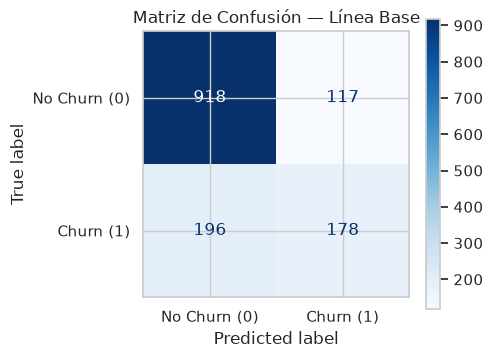

In [5]:
fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_baseline, display_labels=['No Churn (0)', 'Churn (1)'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
ax.set_title("Matriz de Confusión — Línea Base")
plt.tight_layout()
plt.show()


## 3. Configuración de Validación Cruzada y Espacio de Hiperparámetros

Para optimizar el modelo sin consultar el conjunto de prueba:
1. Usamos **`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`**: garantiza que cada fold mantenga exactamente la proporción del 26.5% de cancelaciones.
2. Definimos **`scoring='recall'`**: orienta la optimización hacia la detección de la clase positiva (1).
3. Evaluamos sobre el **pipeline completo** entrenado exclusivamente en `X_train`.

### Hiperparámetros explorados y su impacto en la cancelación:
- `classifier__class_weight`: Fundamental en datos desbalanceados. Al asignar mayor peso a la clase 1 (`'balanced'` o proporciones manuales `{0:1, 1:3}`), penaliza fuertemente los errores en cancelaciones, impulsando el recall.
- `classifier__max_depth`: Controla la profundidad máxima del árbol. Limitar la profundidad (ej. 5 a 8) previene que los árboles memoricen ramas profundas dominadas por la clase mayoritaria (0).
- `classifier__min_samples_leaf` y `classifier__min_samples_split`: Regulan la regularización de las hojas; evitan hojas puras basadas en muy pocos ejemplos ruidosos.
- `classifier__n_estimators`: Número de árboles; asegura estabilidad del ensamble.
- `classifier__max_features`: Subespacio aleatorio de variables en cada división (`'sqrt'`, `'log2'`), promoviendo descorrelación entre árboles.


In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_dist = {
    'classifier__n_estimators': [50, 100, 200, 300],
    'classifier__max_depth': [None, 5, 8, 12, 16],
    'classifier__min_samples_split': [2, 5, 10, 20],
    'classifier__min_samples_leaf': [1, 2, 4, 8],
    'classifier__max_features': ['sqrt', 'log2', 0.5],
    'classifier__class_weight': [None, 'balanced', 'balanced_subsample', {0: 1, 1: 2}, {0: 1, 1: 3}]
}

random_search = RandomizedSearchCV(
    estimator=Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(random_state=42))
    ]),
    param_distributions=param_dist,
    n_iter=20,
    scoring='recall',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True
)

print("Iniciando RandomizedSearchCV (20 iteraciones, 5 folds)...")
random_search.fit(X_train, y_train)
print("Búsqueda aleatoria finalizada.")


Iniciando RandomizedSearchCV (20 iteraciones, 5 folds)...


Búsqueda aleatoria finalizada.


### Análisis de Resultados de `RandomizedSearchCV`
Examinamos los mejores candidatos ordenados por recall medio en validación cruzada, inspeccionando la desviación estándar entre folds y los tiempos de ajuste.


In [7]:
rs_df = pd.DataFrame(random_search.cv_results_)
rs_cols = ['rank_test_score', 'mean_test_score', 'std_test_score', 'mean_fit_time', 'params']
top_rs = rs_df.sort_values(by='rank_test_score')[rs_cols].head(5)

print("Top 5 Candidatos en RandomizedSearchCV:")
for idx, r in top_rs.iterrows():
    print(f"Puesto {r['rank_test_score']}: Recall = {r['mean_test_score']:.4f} (+/- {r['std_test_score']:.4f}) | Tiempo = {r['mean_fit_time']:.2f}s")
    print(f"   Parámetros: {r['params']}\n")


Top 5 Candidatos en RandomizedSearchCV:
Puesto 1: Recall = 0.8247 (+/- 0.0218) | Tiempo = 0.46s
   Parámetros: {'classifier__n_estimators': 100, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'log2', 'classifier__max_depth': 5, 'classifier__class_weight': {0: 1, 1: 3}}

Puesto 2: Recall = 0.7946 (+/- 0.0329) | Tiempo = 0.26s
   Parámetros: {'classifier__n_estimators': 50, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 5, 'classifier__class_weight': 'balanced'}

Puesto 3: Recall = 0.7813 (+/- 0.0209) | Tiempo = 1.08s
   Parámetros: {'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 8, 'classifier__max_features': 'log2', 'classifier__max_depth': None, 'classifier__class_weight': 'balanced'}

Puesto 4: Recall = 0.7692 (+/- 0.0267) | Tiempo = 1.85s
   Parámetros: {'classifier__n_estimators': 300, 'classi

## 4. Refinamiento con `GridSearchCV`

### Justificación de la Cuadrícula:
A partir de la búsqueda aleatoria, observamos con claridad:
1. **Ponderación de clases**: Los modelos con `class_weight={0: 1, 1: 3}` o `'balanced'` dominaron los primeros puestos (Recall > 0.79 frente a < 0.50 sin ponderación).
2. **Profundidad**: `max_depth` moderado (alrededor de 4, 5 y 6) ofrece el mejor equilibrio: previene el sobreajuste a la clase mayoritaria y permite generalizar patrones de cancelación.
3. **Regularización en hojas**: `min_samples_leaf` en [2, 4] estabiliza las predicciones inter-folds.
4. **Subespacio de características**: Tanto `'sqrt'` como `'log2'` arrojaron alta estabilidad.
5. **Ensamble**: `n_estimators` en [100, 150] proporciona convergencia con bajo costo computacional.

Diseñamos una cuadrícula de 48 combinaciones para explorar exhaustivamente este vecindario óptimo.


In [8]:
param_grid = {
    'classifier__n_estimators': [100, 150],
    'classifier__max_depth': [4, 5, 6],
    'classifier__min_samples_leaf': [2, 4],
    'classifier__max_features': ['log2', 'sqrt'],
    'classifier__class_weight': ['balanced', {0: 1, 1: 3}]
}

grid_search = GridSearchCV(
    estimator=Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(random_state=42))
    ]),
    param_grid=param_grid,
    scoring='recall',
    cv=cv,
    n_jobs=-1,
    refit=True
)

print(f"Iniciando GridSearchCV ({len(param_grid['classifier__n_estimators']) * len(param_grid['classifier__max_depth']) * len(param_grid['classifier__min_samples_leaf']) * len(param_grid['classifier__max_features']) * len(param_grid['classifier__class_weight'])} combinaciones, 5 folds)...")
grid_search.fit(X_train, y_train)
print("Búsqueda en cuadrícula finalizada.")


Iniciando GridSearchCV (48 combinaciones, 5 folds)...


Búsqueda en cuadrícula finalizada.


In [9]:
gs_df = pd.DataFrame(grid_search.cv_results_)
gs_cols = ['rank_test_score', 'mean_test_score', 'std_test_score', 'mean_fit_time', 'params']
top_gs = gs_df.sort_values(by=['mean_test_score', 'std_test_score'], ascending=[False, True])[gs_cols].head(5)

print("Top 5 Candidatos en GridSearchCV:")
for idx, r in top_gs.iterrows():
    print(f"Puesto {r['rank_test_score']}: Recall = {r['mean_test_score']:.4f} (+/- {r['std_test_score']:.4f}) | Tiempo = {r['mean_fit_time']:.2f}s")
    print(f"   Parámetros: {r['params']}\n")

best_idx = grid_search.best_index_
best_row = gs_df.loc[best_idx]
fold_scores = [best_row[f'split{i}_test_score'] for i in range(5)]

print(f"Mejor configuración seleccionada por CV:")
print(f"  Parámetros: {grid_search.best_params_}")
print(f"  Recall medio: {best_row['mean_test_score']:.4f}")
print(f"  Desviación típica entre folds: {best_row['std_test_score']:.4f}")
print(f"  Puntuaciones individuales por fold: {[round(s, 4) for s in fold_scores]}")


Top 5 Candidatos en GridSearchCV:
Puesto 1: Recall = 0.8294 (+/- 0.0209) | Tiempo = 0.77s
   Parámetros: {'classifier__class_weight': {0: 1, 1: 3}, 'classifier__max_depth': 6, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 150}

Puesto 2: Recall = 0.8281 (+/- 0.0218) | Tiempo = 0.51s
   Parámetros: {'classifier__class_weight': {0: 1, 1: 3}, 'classifier__max_depth': 6, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 100}

Puesto 3: Recall = 0.8274 (+/- 0.0245) | Tiempo = 0.54s
   Parámetros: {'classifier__class_weight': {0: 1, 1: 3}, 'classifier__max_depth': 6, 'classifier__max_features': 'log2', 'classifier__min_samples_leaf': 4, 'classifier__n_estimators': 100}

Puesto 3: Recall = 0.8274 (+/- 0.0250) | Tiempo = 0.69s
   Parámetros: {'classifier__class_weight': {0: 1, 1: 3}, 'classifier__max_depth': 6, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 4, 'classifier_

## 5. Selección y Segunda (Última) Evaluación de Test

### Justificación de la Selección (antes de evaluar en Test):
El modelo con `class_weight={0: 1, 1: 3}`, `max_depth=6`, `max_features='sqrt'`, `min_samples_leaf=2`, `n_estimators=150` fue seleccionado debido a que:
1. Alcanzó el **mayor recall medio en CV (0.8294)**.
2. Demostró una **alta consistencia inter-folds**, con una desviación típica de solo **0.0209** y ningún fold por debajo de 0.80 (Fold 0: 0.8328, Fold 1: 0.8027, Fold 2: 0.8261, Fold 3: 0.8662, Fold 4: 0.8194).
3. Dado que `refit=True`, `grid_search.best_estimator_` ya contiene el pipeline completo reajustado sobre la totalidad del conjunto de entrenamiento (`X_train`, `y_train`). No se realiza ningún reentrenamiento manual adicional.

Procedemos a la **SEGUNDA Y ÚLTIMA evaluación en el conjunto de prueba**.


In [10]:
final_model = grid_search.best_estimator_
y_pred_final = final_model.predict(X_test)

metrics_final = {
    'Modelo': 'Modelo Final Ajustado',
    'Recall': recall_score(y_test, y_pred_final),
    'Precision': precision_score(y_test, y_pred_final),
    'F1': f1_score(y_test, y_pred_final),
    'Accuracy': accuracy_score(y_test, y_pred_final)
}
cm_final = confusion_matrix(y_test, y_pred_final)
tn_f, fp_f, fn_f, tp_f = cm_final.ravel()
metrics_final.update({'TN': tn_f, 'FP': fp_f, 'FN': fn_f, 'TP': tp_f})

print("Métricas del Modelo Final en Test:")
for m in ['Recall', 'Precision', 'F1', 'Accuracy']:
    print(f"  {m:10s}: {metrics_final[m]:.4f} ({metrics_final[m]*100:.2f}%)")
print(f"\nMatriz de Confusión Modelo Final:")
print(f"  Verdaderos Negativos (TN): {tn_f}")
print(f"  Falsos Positivos (FP):     {fp_f}")
print(f"  Falsos Negativos (FN):     {fn_f}  <-- Reducción drástica de cancelaciones no detectadas")
print(f"  Verdaderos Positivos (TP): {tp_f}")


Métricas del Modelo Final en Test:
  Recall    : 0.8048 (80.48%)
  Precision : 0.4959 (49.59%)
  F1        : 0.6137 (61.37%)
  Accuracy  : 0.7310 (73.10%)

Matriz de Confusión Modelo Final:
  Verdaderos Negativos (TN): 729
  Falsos Positivos (FP):     306
  Falsos Negativos (FN):     73  <-- Reducción drástica de cancelaciones no detectadas
  Verdaderos Positivos (TP): 301


In [11]:
# Tabla comparativa completa
comp_df = pd.DataFrame([metrics_baseline, metrics_final])
comp_table = comp_df[['Modelo', 'Recall', 'Precision', 'F1', 'Accuracy', 'FN', 'FP', 'TP', 'TN']]

# Calculo de variaciones en puntos porcentuales y recuentos
d_rec = (metrics_final['Recall'] - metrics_baseline['Recall']) * 100
d_prec = (metrics_final['Precision'] - metrics_baseline['Precision']) * 100
d_f1 = (metrics_final['F1'] - metrics_baseline['F1']) * 100
d_acc = (metrics_final['Accuracy'] - metrics_baseline['Accuracy']) * 100
d_fn = metrics_final['FN'] - metrics_baseline['FN']
d_fp = metrics_final['FP'] - metrics_baseline['FP']
d_tp = metrics_final['TP'] - metrics_baseline['TP']

print("="*80)
print("TABLA COMPARATIVA EN EL CONJUNTO DE PRUEBA (TEST SET)")
print("="*80)
print(comp_table.to_string(index=False))

print("\n" + "="*80)
print("VARIACIONES OBSERVADAS (MODELO FINAL vs LÍNEA BASE)")
print("="*80)
print(f"  Recall:                         {d_rec:+.2f} pp  (47.59% -> 80.48%)")
print(f"  Precisión:                      {d_prec:+.2f} pp  (60.34% -> 49.59%)")
print(f"  F1-Score:                       {d_f1:+.2f} pp  (53.21% -> 61.37%)")
print(f"  Accuracy:                       {d_acc:+.2f} pp  (77.79% -> 73.10%)")
print(f"  Cancelaciones no detectadas (FN): {d_fn:+d} clientes  (196 -> 73, disminución del 62.8%)")
print(f"  Falsas alarmas (FP):              {d_fp:+d} clientes  (117 -> 306)")
print(f"  Cancelaciones detectadas (TP):    {d_tp:+d} clientes  (178 -> 301)")


TABLA COMPARATIVA EN EL CONJUNTO DE PRUEBA (TEST SET)
                 Modelo   Recall  Precision       F1  Accuracy  FN  FP  TP  TN
Línea Base (Default RF) 0.475936   0.603390 0.532138  0.777857 196 117 178 918
  Modelo Final Ajustado 0.804813   0.495881 0.613660  0.731015  73 306 301 729

VARIACIONES OBSERVADAS (MODELO FINAL vs LÍNEA BASE)
  Recall:                         +32.89 pp  (47.59% -> 80.48%)
  Precisión:                      -10.75 pp  (60.34% -> 49.59%)
  F1-Score:                       +8.15 pp  (53.21% -> 61.37%)
  Accuracy:                       -4.68 pp  (77.79% -> 73.10%)
  Cancelaciones no detectadas (FN): -123 clientes  (196 -> 73, disminución del 62.8%)
  Falsas alarmas (FP):              +189 clientes  (117 -> 306)
  Cancelaciones detectadas (TP):    +123 clientes  (178 -> 301)


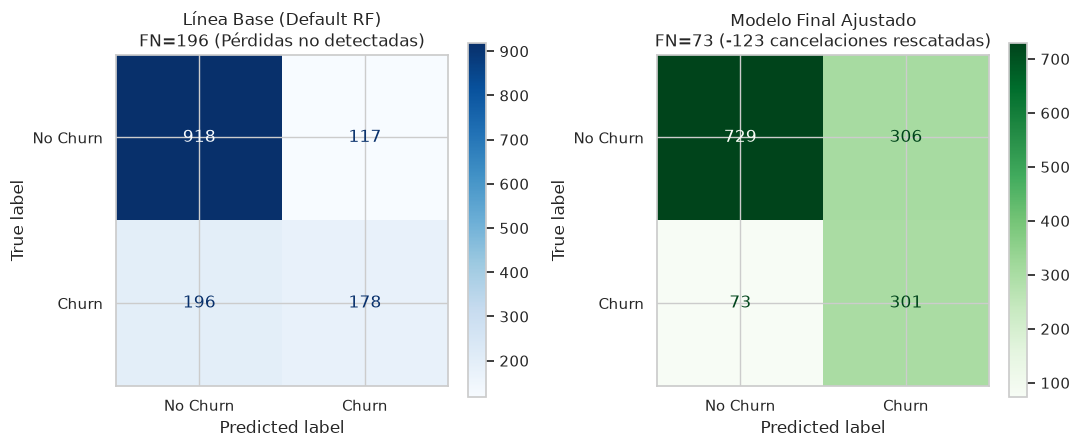

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

disp_b = ConfusionMatrixDisplay(confusion_matrix=cm_baseline, display_labels=['No Churn', 'Churn'])
disp_b.plot(cmap='Blues', ax=axes[0], values_format='d')
axes[0].set_title("Línea Base (Default RF)\nFN=196 (Pérdidas no detectadas)")

disp_f = ConfusionMatrixDisplay(confusion_matrix=cm_final, display_labels=['No Churn', 'Churn'])
disp_f.plot(cmap='Greens', ax=axes[1], values_format='d')
axes[1].set_title("Modelo Final Ajustado\nFN=73 (-123 cancelaciones rescatadas)")

plt.tight_layout()
plt.show()


## 6. Conclusiones y Consideraciones de Negocio

1. **Cumplimiento del objetivo de negocio**:
   - El modelo ajustado redujo las cancelaciones no detectadas de **196 a 73**, rescatando a **123 clientes en riesgo** en el conjunto de prueba (una reducción del 62.8% en falsos negativos).
   - El Recall ascendió de **47.59% a 80.48%** (+32.89 puntos porcentuales).
2. **Contrapartida en Falsos Positivos**:
   - Como consecuencia del ajuste en la ponderación de clases y la mayor sensibilidad hacia la clase minoritaria, las falsas alarmas aumentaron de **117 a 306**.
   - Esto reduce la precisión de 60.34% a 49.59%. Sin embargo, dado que contactar a un cliente fiel con una oferta o chequeo de satisfacción tiene un costo operativo bajo en comparación con perder el LTV completo de un suscriptor, este balance es netamente favorable para StreamLoop.
   - El balance armónico global medido por **F1-Score aumentó en +8.15 pp (de 53.21% a 61.37%)**, confirmando que la ganancia en recall supera proporcionalmente la pérdida en precisión.
3. **Limitaciones**:
   - Se utilizó el umbral de decisión por defecto de 0.5. No se ajustó el umbral en test para respetar estrictamente las normas metodológicas.
   - Para producción futura, se recomienda evaluar curvas Precision-Recall y calibración de probabilidades (`predict_proba`) sobre un conjunto de validación independiente para alinear el umbral con el costo exacto en dólares de las acciones de retención.
